# ThAr IP analysis for jaxstar: Chebyshev mixture

Run the cells in order: select the ThAr line windows, choose a Chebyshev degree for each order by BIC_MAP, optionally sample the selected model with NUTS, inspect the diagnostic plots, and save the results.

Each line's IP is exactly the Chebyshev prediction at its reference wavelength. Independent least-squares fits are retained as comparison points. Restart the kernel after updating the package.

For a constant IP within each order, see [the common-IP notebook](thar_ip_analysis_common_for_jaxstar.ipynb). The final section runs this Chebyshev workflow in one call as an alternative to the individual steps.


## Setup


In [1]:
from pathlib import Path
from dataclasses import replace
from time import perf_counter
from datetime import datetime
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/gaoesrvip').is_dir())
sys.path.insert(0, str(repo / 'src'))
from gaoesrvip import select_lines, fit, load_result
print('Repository:', repo)


Repository: .


## Input data and fit settings

Choose the orders, candidate degrees, detector settings and whether to run NUTS after selecting the best MAP for each order.

`fit_spectrum` points to the ThAr pickle. The step-by-step cells display each diagnostic figure. The final one-call section saves the results and figures without displaying them.


In [2]:
thar = repo / 'data/ThAr20251107_2.center.fits'
wavelength_file = repo / 'data/ecThAr20251107_2.center'
fit_spectrum = repo / 'data/ThAr20251107_1_ip.pkl'
gain = 1.0
read_noise = 4.0
half_window = 7
saturation = 51000
blend_guard = 2.0
baseline_degree = 1

orders = [104, 105, 106]  # use list(range(101, 116)) for all orders
max_degree = 4
degrees = range(max_degree+1)  # candidate degrees; selected independently per order
run_nuts = False
warmup, samples, chains, seed = 500, 500, 1, 0
min_inlier_probability = 0.5
ci = 0.68
plot_n_positions = 500
zoom_outliers = True
output_root = repo / 'examples/results/thar_ip_analysis_chebyshev_for_jaxstar'

## Select lines

Use the central spectrum and its database for blend/saturation selection, then extract windows from `fit_spectrum` for fitting. The ThAr pickle uses its `lam` and `flux` columns, with the header's valid lengths; `fflux` and padded tails are not used. An ecfw FITS can be supplied through the same argument. No preliminary screening fit is applied.


In [3]:
data = select_lines(
    thar, wavelength_file, fit_spectrum=fit_spectrum,
    orders=orders, gain=gain, read_noise=read_noise,
    saturation=saturation, half_window=half_window, blend_guard=blend_guard,
)

## Fit the Chebyshev IP

Optimize each candidate degree separately for each order, and retain the MAP with the smallest BIC_MAP. The score uses `-2 logL(MAP) + k log(n)`, with all valid fitted pixels counted in `n` and coefficients, local parameters and three mixture parameters counted in `k`. All degrees use the same selected lines. This is a BIC-like comparison at the MAP, not maximum-likelihood BIC.

The selected degree is printed once per order. The complete comparison remains available in `scores` and is saved as CSV. Failed candidates are recorded and excluded; an order with no converged candidate stops the fit.


In [4]:
started = perf_counter()
chebyshev_map = fit(
    data, mode='chebyshev', degrees=degrees,
    baseline_degree=baseline_degree, nuts=False, seed=seed, progress=True,
)
map_seconds = perf_counter() - started
scores = chebyshev_map.degree_scores
best_degrees = {o.data.order: o.chebyshev.degree for o in chebyshev_map.orders}
print(f'Degree search: {map_seconds:.2f} s')


Order 104: degree 2, BIC_MAP=-1926.34 (5/5 candidates converged)
Order 105: degree 1, BIC_MAP=-1511.15 (5/5 candidates converged)
Order 106: degree 1, BIC_MAP=-1440.37 (5/5 candidates converged)
Degree search: 33.00 s


## Optional NUTS at the selected degrees

Set `run_nuts=True` to sample from each stored MAP. Re-running only this cell does not repeat degree selection or any optimization. Coefficients, local flux/background parameters and the mixture scales/fraction are sampled; each order's degree stays fixed. Cumulant credible bands are conditional on those selected degrees.


In [5]:
started = perf_counter()
chebyshev = (
    chebyshev_map.sample_nuts(
        warmup=warmup, samples=samples, chains=chains, seed=seed, progress=True,
    ) if run_nuts else chebyshev_map
)
fit_seconds = map_seconds + perf_counter() - started
figures = {}
if run_nuts:
    print('Inspect the NUTS diagnostics above before interpreting credible intervals.')
print(f'Total fit time: {fit_seconds:.2f} s')


Total fit time: 33.00 s


## Inspect line fits

Each order has one figure showing every selected line, including outliers: data, the two Gaussian components and baseline, and full-window residuals. Colors and titles show `P(outlier)`. Residual percentages use the fixed observed peak.


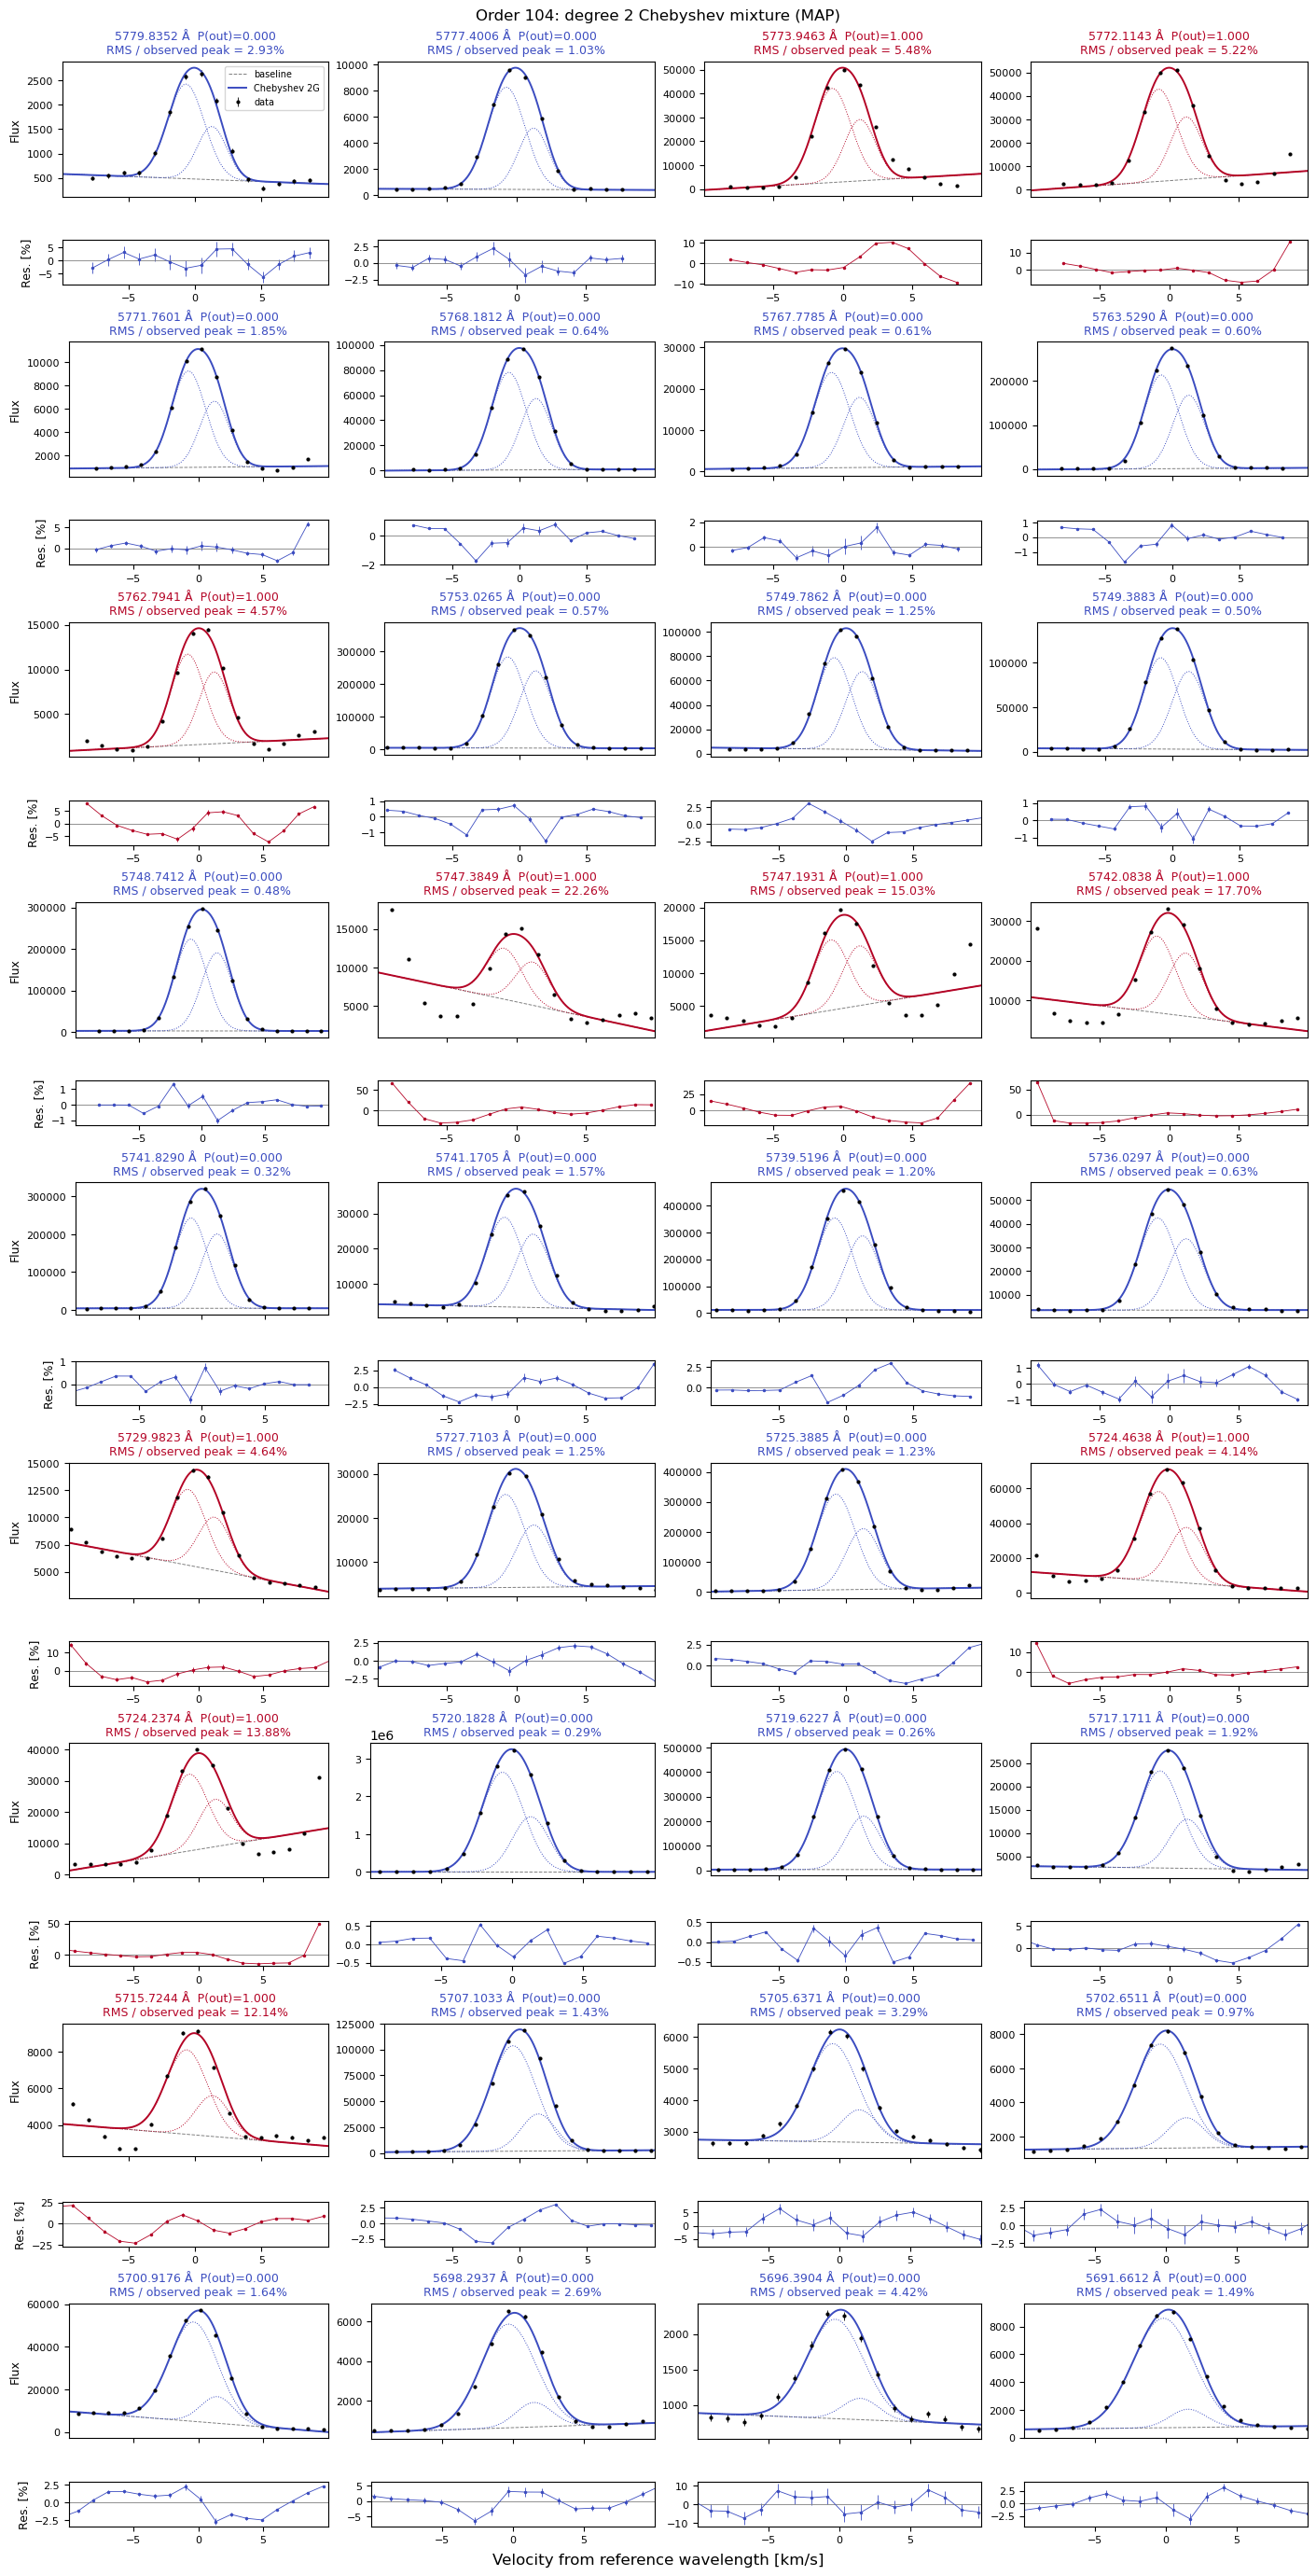

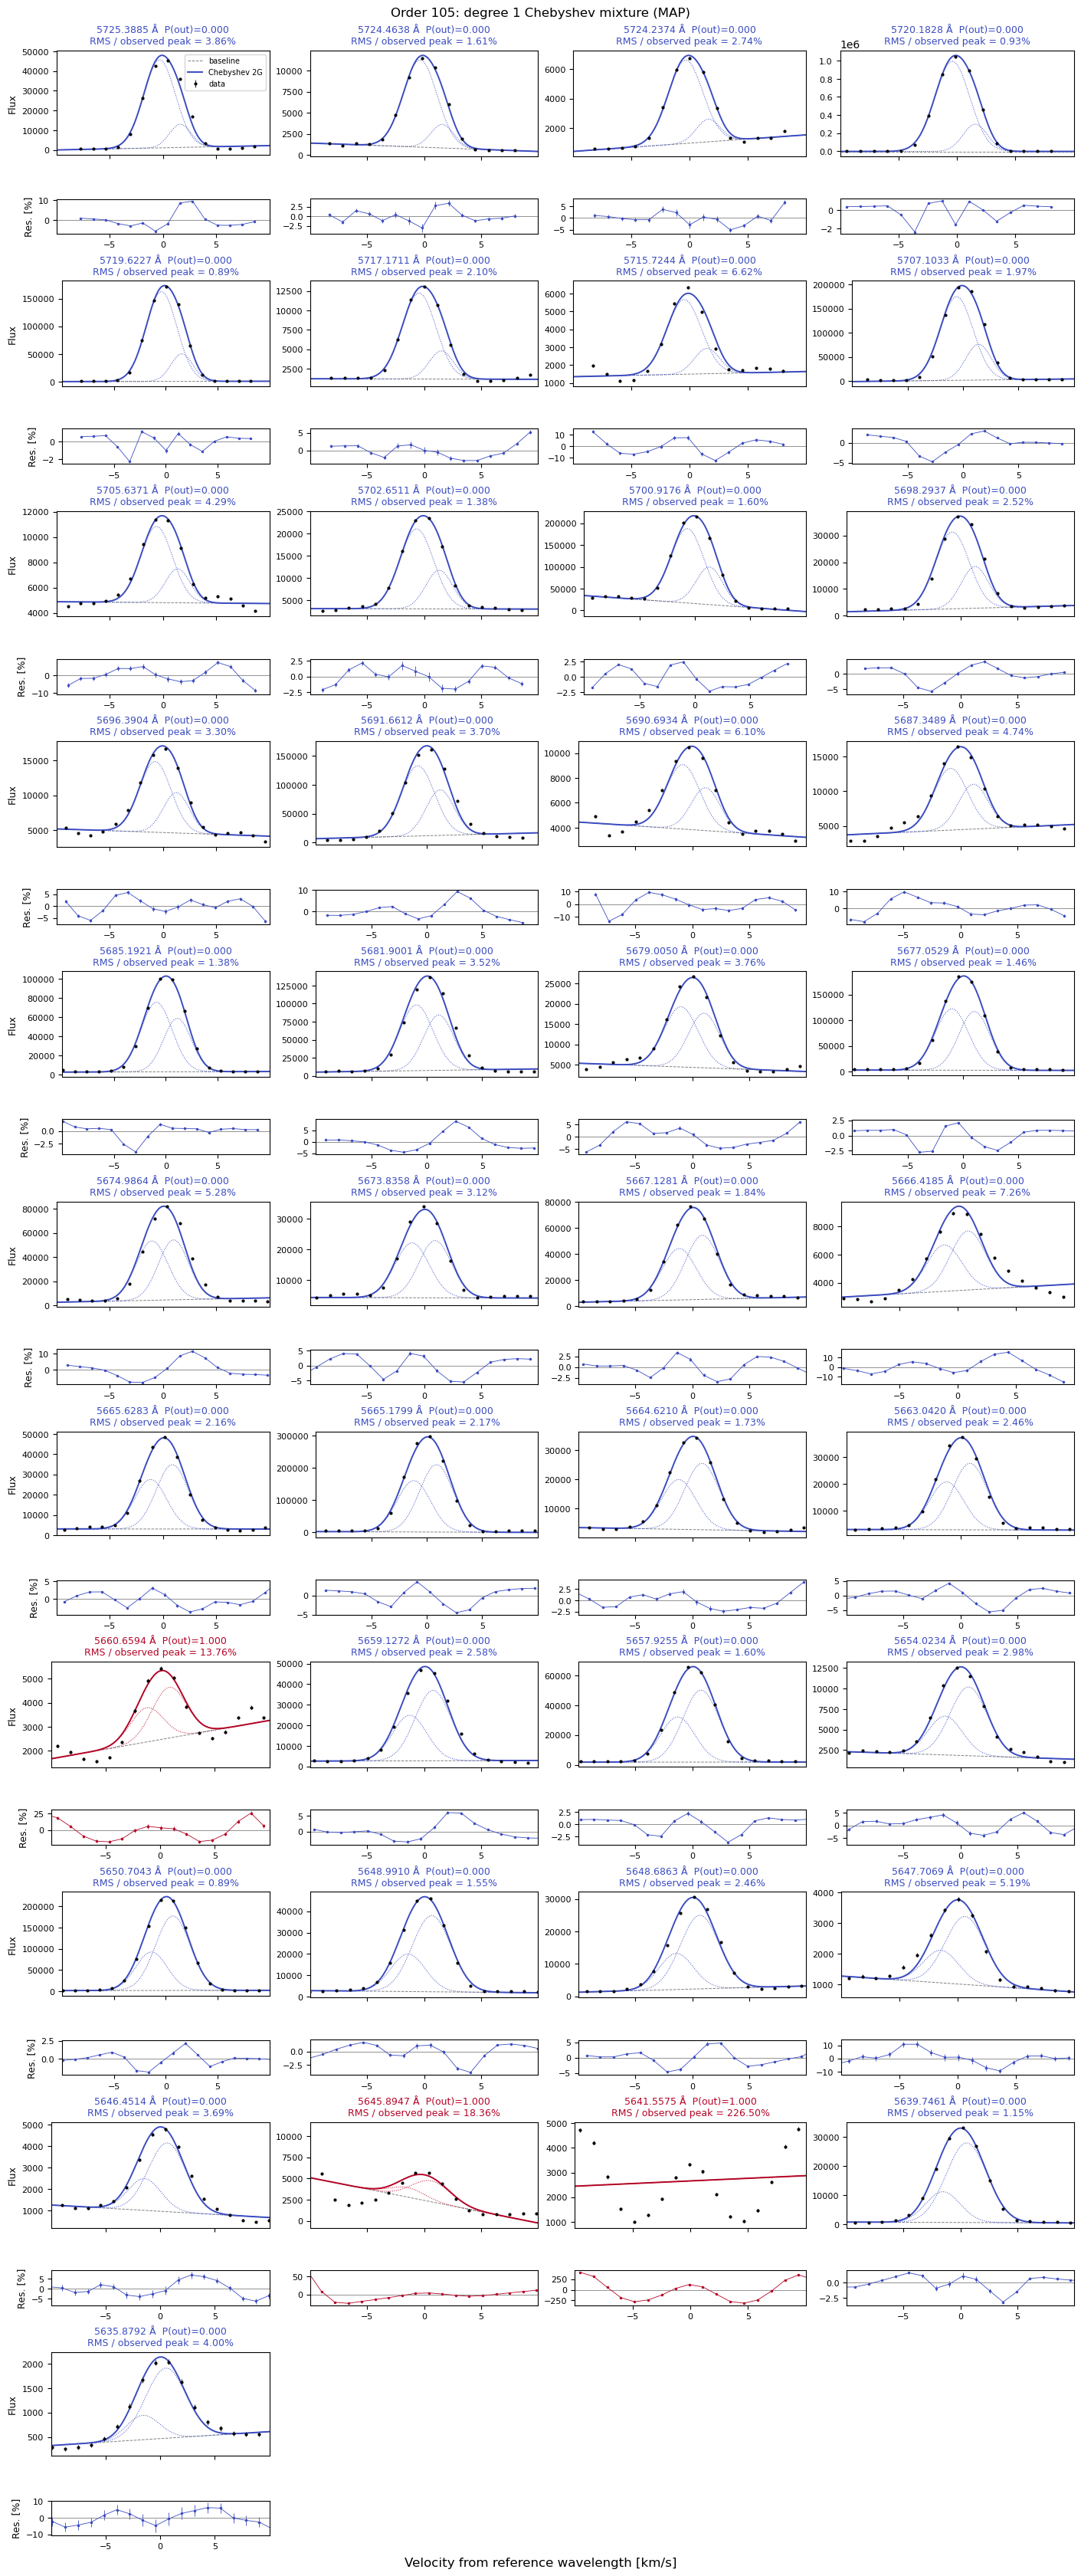

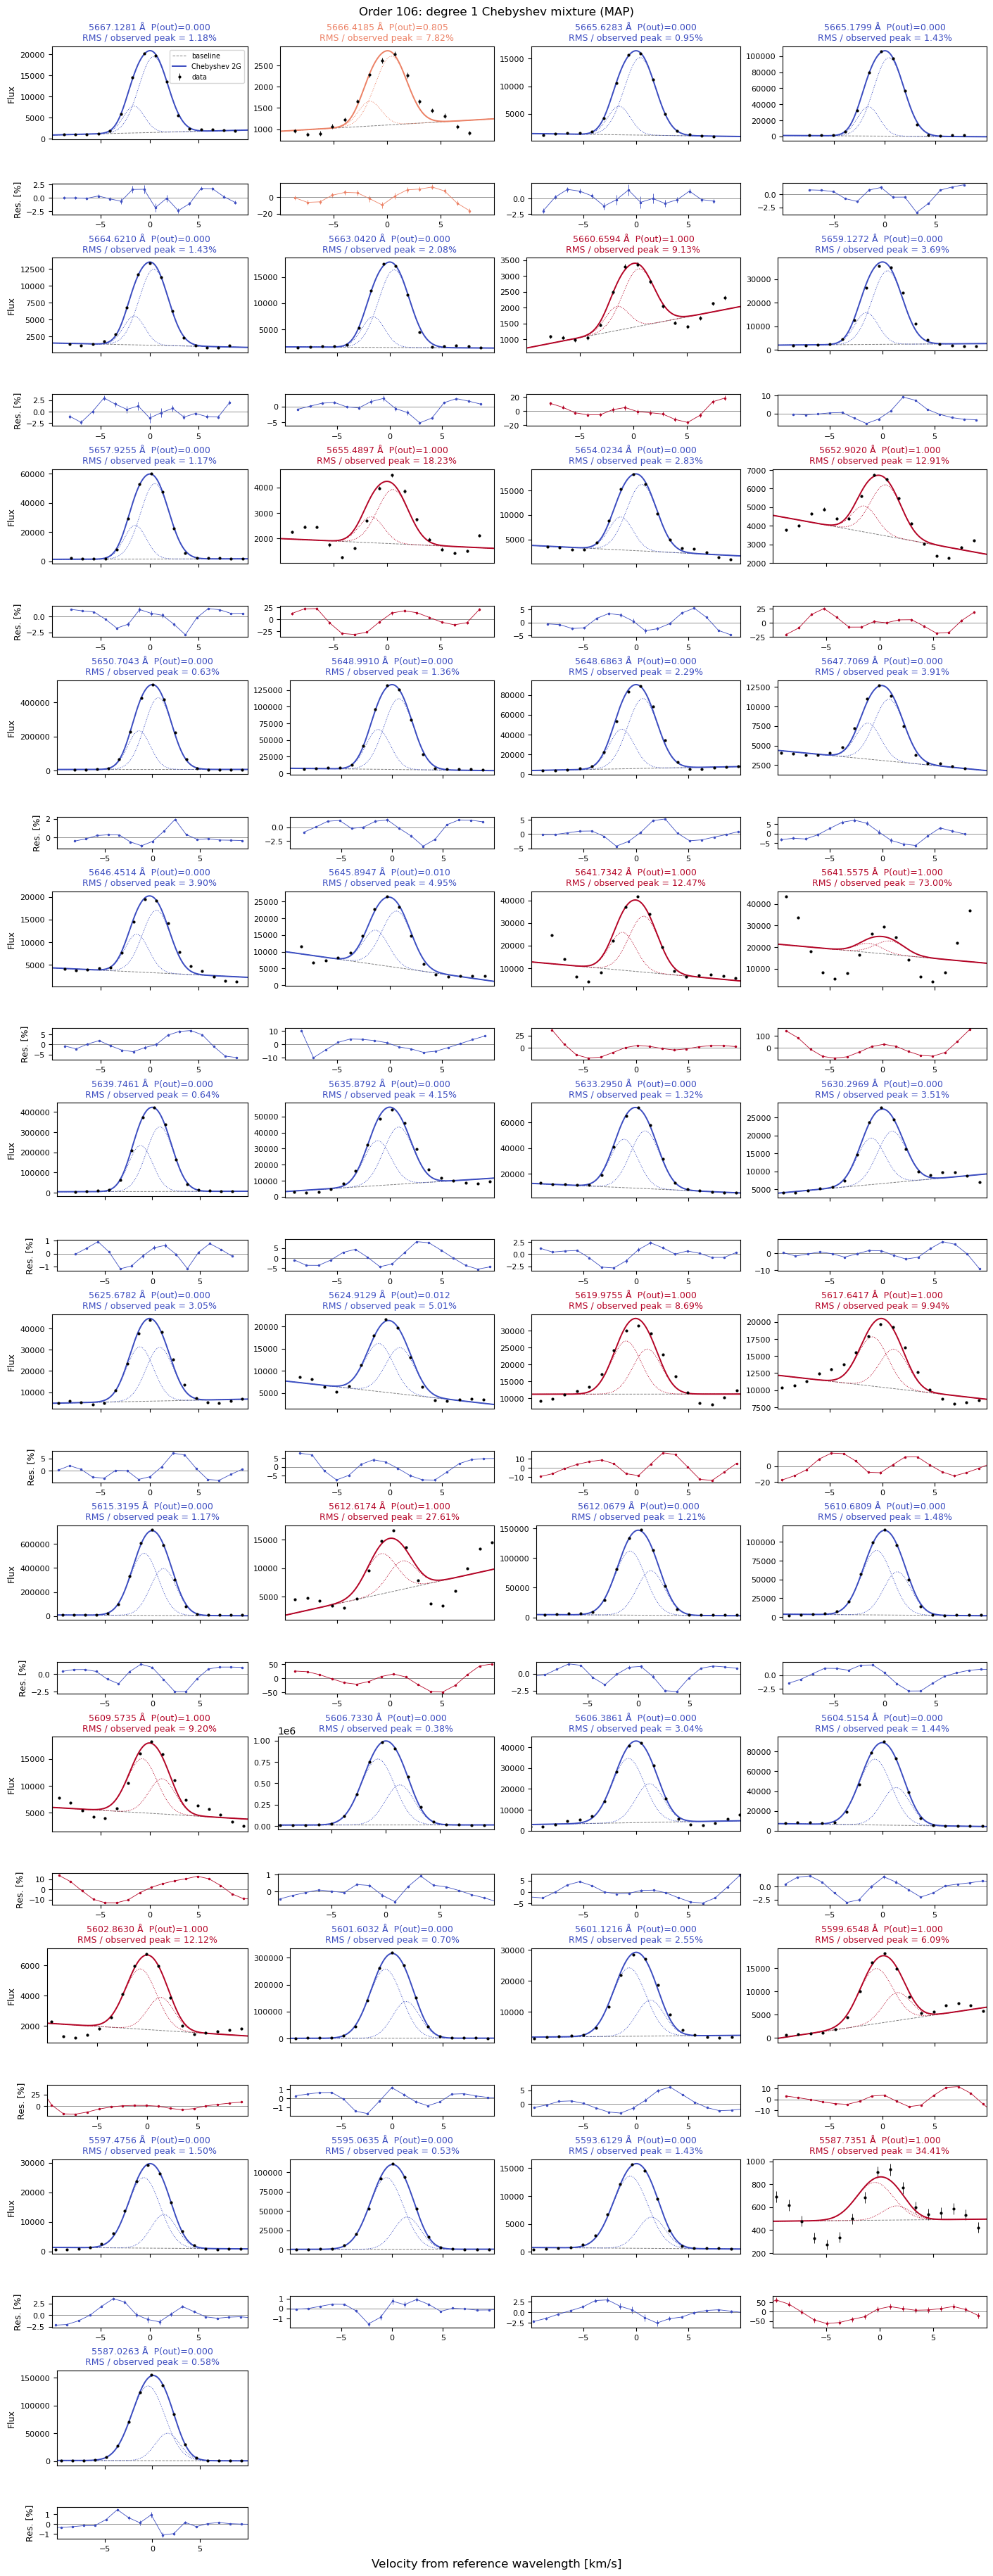

In [6]:
# Replace line figures when replotting, so saved figures follow the current order list.
for name in list(figures):
    if name.startswith('lines_order'):
        del figures[name]
for fitted_order, fig in zip(chebyshev.orders, chebyshev.plot_lines(include_baseline=True)):
    figures[f'lines_order_{fitted_order.data.order}'] = fig
    display(fig)
    plt.close(fig)


## Overlay line profiles

Display one figure per order with `P(inlier) > min_inlier_probability`. This affects the plot only; the saved fit retains all selected lines. Orders with no lines passing the display threshold are skipped. Zero velocity is the reference wavelength, so fitted offsets are retained.


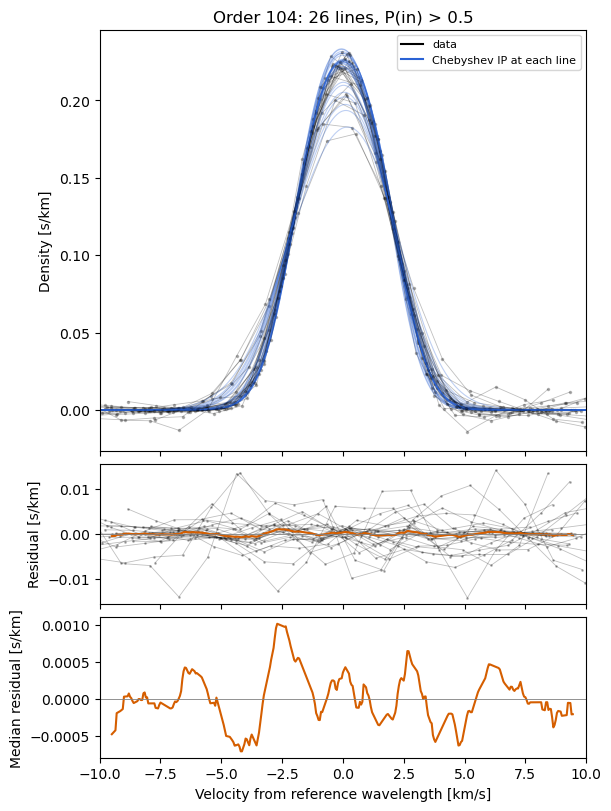

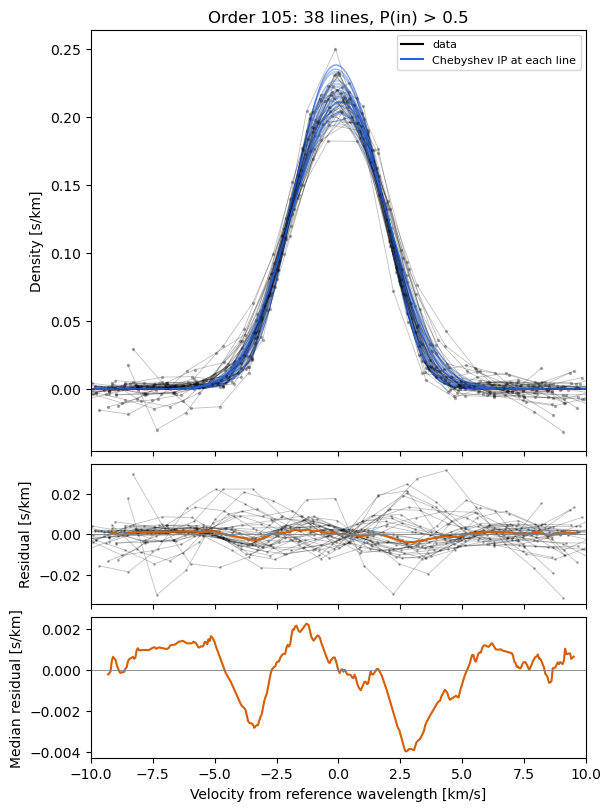

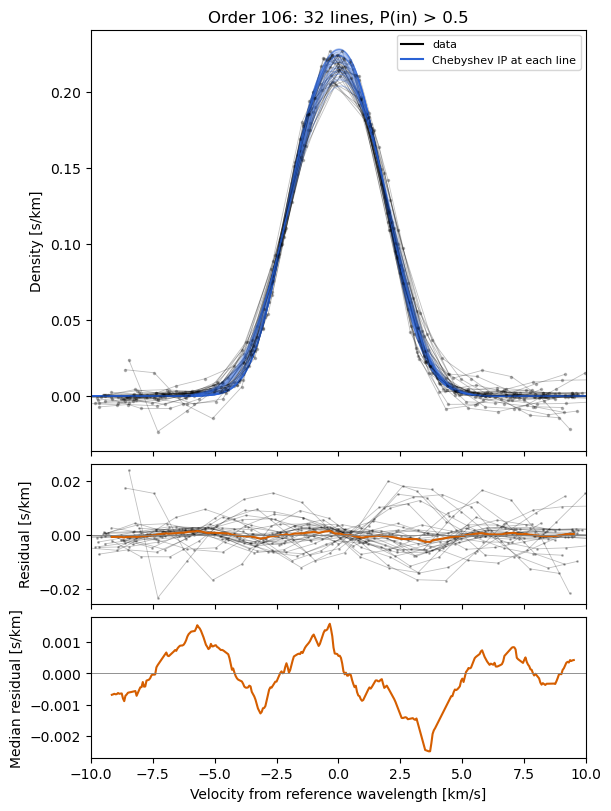

In [7]:
for name in list(figures):
    if name.startswith('overlay_inliers'):
        del figures[name]
for fitted_order in chebyshev.orders:
    if (min_inlier_probability is not None
            and not (fitted_order.chebyshev.inlier_probability > min_inlier_probability).any()):
        continue
    single_order = replace(chebyshev, orders=[fitted_order])
    fig = single_order.overlay(min_inlier_probability=min_inlier_probability)
    figures[f'overlay_inliers_order_{fitted_order.data.order}'] = fig
    display(fig)
    plt.close(fig)


## Inspect IP cumulants

Show one figure per order. Compare the smooth κ₁–κ₅ curves with independent fits, colored by the spectral inlier probability. NUTS results include pointwise credible bands; MAP-only results have no bands. Triangles mark points clipped by the display limits. Set `zoom_outliers=False` to show the full range.


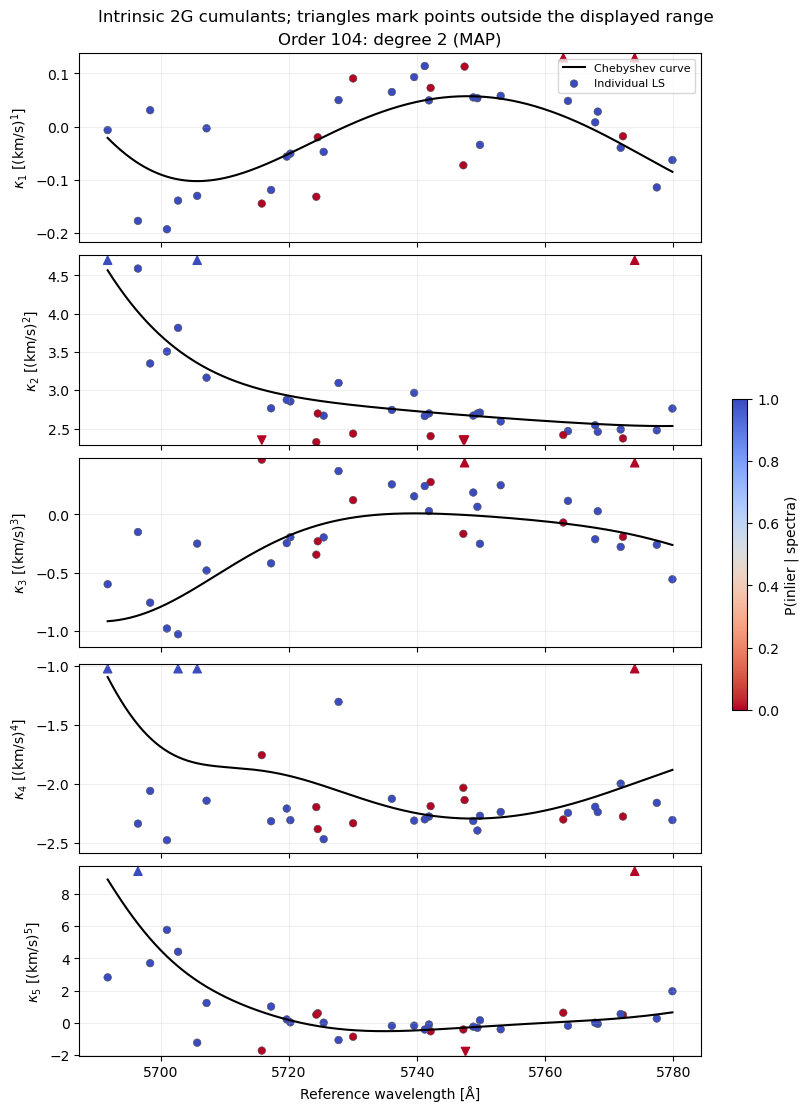

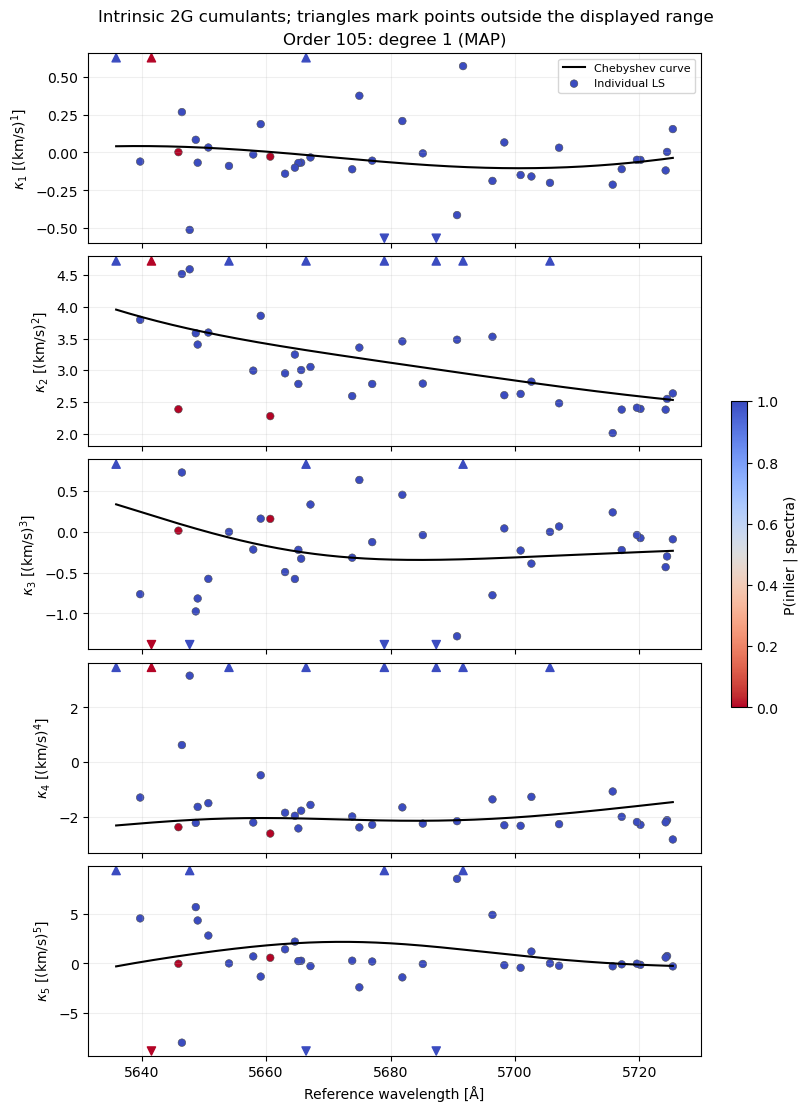

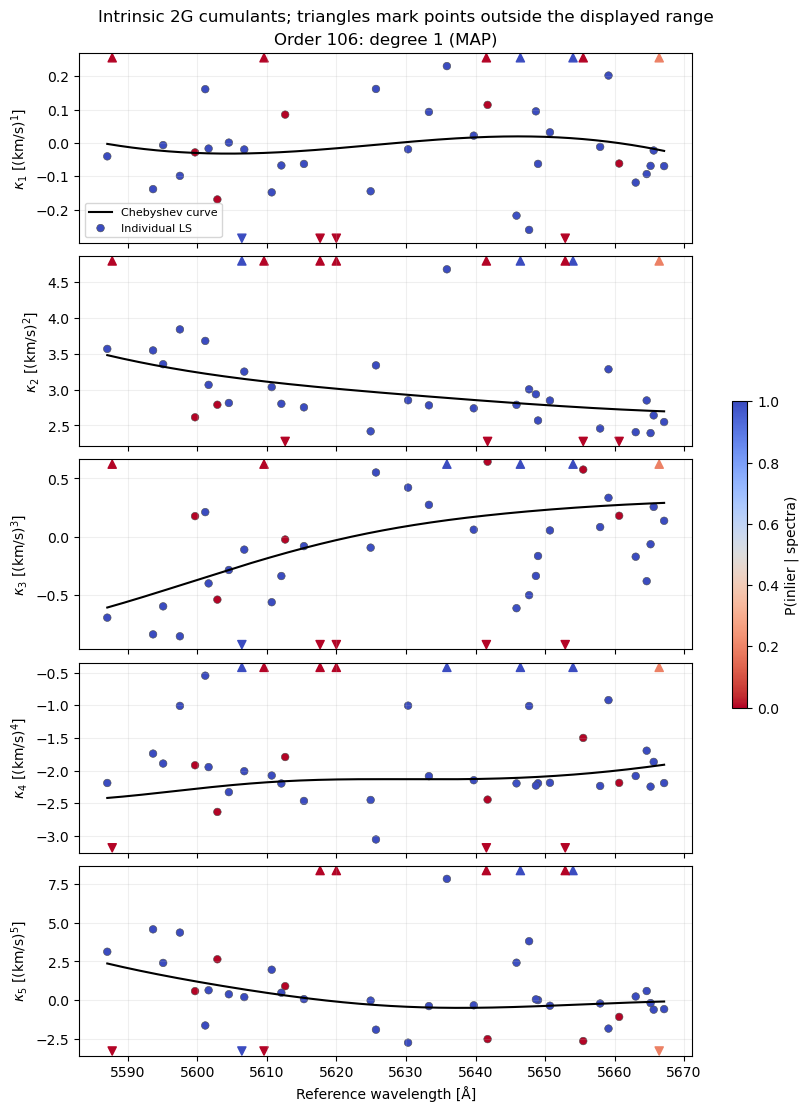

In [8]:
for name in list(figures):
    if name == 'cumulants' or name.startswith('cumulants_order_'):
        del figures[name]
for fitted_order in chebyshev.orders:
    single_order = replace(chebyshev, orders=[fitted_order])
    fig = single_order.plot_cumulants(ci=ci, n_positions=plot_n_positions,
                                      zoom_outliers=zoom_outliers)
    figures[f'cumulants_order_{fitted_order.data.order}'] = fig
    display(fig)
    plt.close(fig)


## Check residual RMS

These are main diagnostic plots. Use all valid fitted pixels: first compare residual RMS against wavelength, relative to the fixed observed peak and supplied noise, with the order legend outside the axes. Then plot observed-peak-normalized RMS against line strength for all orders together on one axis, colored by inlier probability. RMS axes are logarithmic. These are unweighted diagnostics and include model mismatch as well as noise.


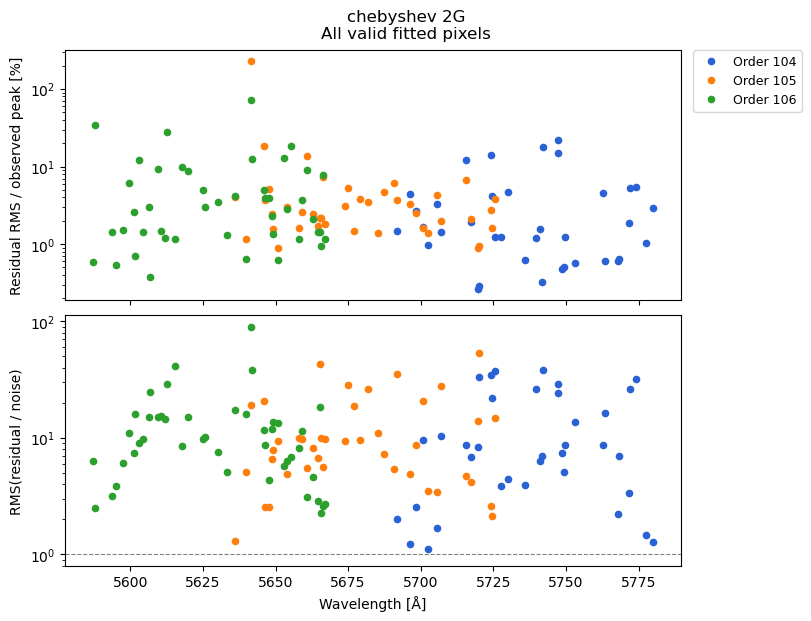

In [9]:
fig = chebyshev.plot_residual_summary()
figures['residual_summary'] = fig
display(fig)
plt.close(fig)


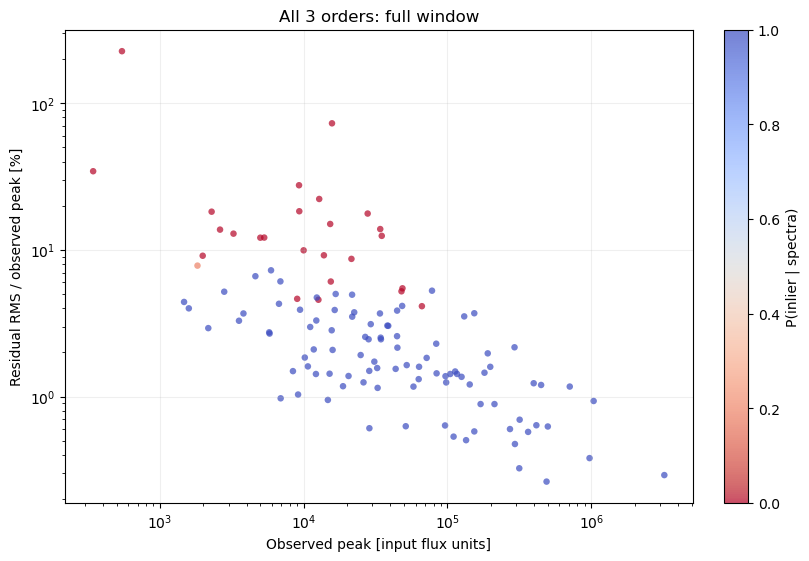

In [10]:
fig = chebyshev.plot_rms_vs_peak()
figures['rms_vs_peak'] = fig
display(fig)
plt.close(fig)


## Save and reload

Save selected degrees, comparison scores, independent fits, MAPs, optional NUTS draws, memberships and diagnostic figures. `degree_scores.csv` records the complete degree search.

For another code, use **`ip_model.json`**: it contains the per-order coefficients and degrees, wavelength domains and normalization, the Chebyshev basis convention, coordinate order and transforms to physical 2G parameters. Coefficients describe the displayed curve (MAP or posterior-median coefficients). Full posterior draws remain in the fit NPZ files. No wavelength prediction grid is stored.


In [11]:
order_tag = 'orders_' + '_'.join(str(o.data.order) for o in chebyshev.orders)
output_dir = output_root / order_tag / 'bic_map' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
chebyshev.save(output_dir, figures=False)
figure_dir = output_dir / 'figures'
figure_dir.mkdir()
for name, fig in figures.items():
    fig.savefig(figure_dir / f'{name}.png', dpi=160, bbox_inches='tight')
print('Saved:', output_dir)


Saved: examples/results/thar_ip_analysis_chebyshev_for_jaxstar/orders_104_105_106/bic_map/20261104_001440_595793


In [12]:
restored = load_result(output_dir)
assert restored.ip_model == chebyshev.ip_model
assert {o.data.order: o.chebyshev.degree for o in restored.orders} == best_degrees
pd.testing.assert_frame_equal(restored.degree_scores, scores)
print('Reloaded coefficients, selected degrees and comparison scores; no refitting.')


Reloaded coefficients, selected degrees and comparison scores; no refitting.


## Reference: cumulants overlaid across all orders

This supplementary view reuses the fitted result. The legend gives the degree selected for each order. Curves, points and any credible bands share each order's color. Small dots have `P(inlier) > 0.5`; faint crosses indicate the remaining points. Each curve stays within its own fitted wavelength range. Triangles indicate clipped points.


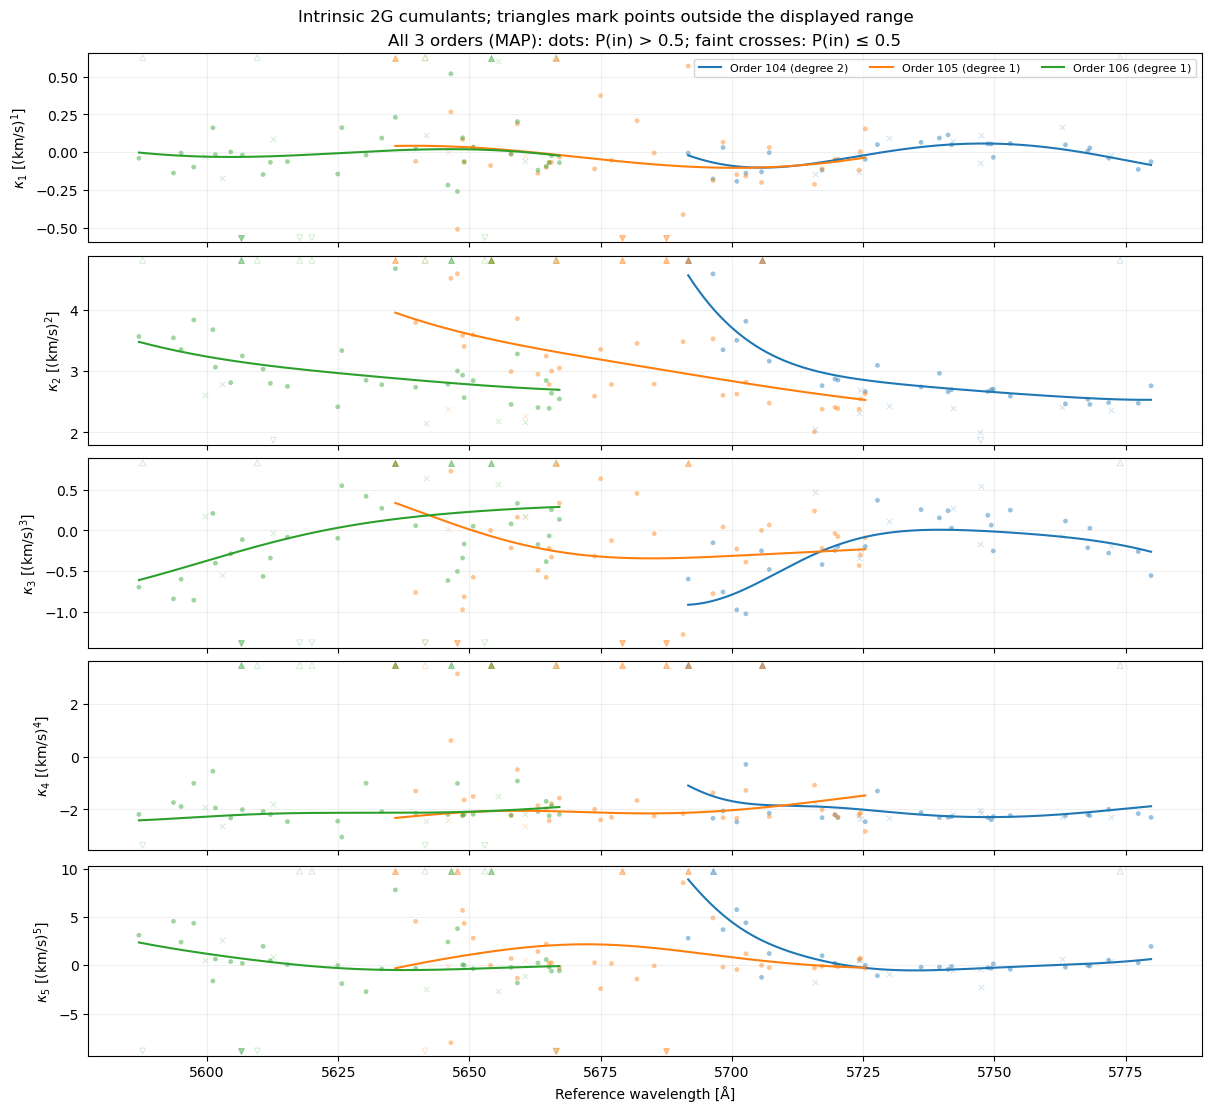

In [13]:
fig = chebyshev.plot_cumulants(
    overlay_orders=True, ci=ci, n_positions=plot_n_positions,
    zoom_outliers=zoom_outliers,
)
figures['cumulants_all_orders'] = fig
display(fig)
plt.close(fig)
fig.savefig(figure_dir / 'cumulants_all_orders.png', dpi=160, bbox_inches='tight')


## Run the full analysis in one call

This is an alternative to the individual steps above: after running the setup and input-settings cells, run this cell to select lines, fit all degrees from 0 through `max_degree` for each order, keep the smallest BIC_MAP, optionally sample the selected MAPs, and save the coefficients, basis information and diagnostic figures. This performs a fresh fit; it does not reuse `chebyshev` from the earlier cells. Figures are saved under `analysis_output_dir / "figures"` with one overlay and cumulant figure per order, both RMS diagnostics, and the final all-order cumulant overlay.

Set `run_nuts=True` for posterior sampling at the selected degrees. For a fixed degree, replace `max_degree=max_degree` with `degree=2`; do not pass both. Each execution uses a new timestamped directory. This call does not require `corner`.


In [14]:
from gaoesrvip import analyze_thar_ip_2g

analysis_order_tag = 'orders_' + '_'.join(str(order) for order in orders)
analysis_output_dir = (output_root / analysis_order_tag / 'one_call'
                       / datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
analysis_result = analyze_thar_ip_2g(
    thar, wavelength_file, analysis_output_dir,
    fit_spectrum=fit_spectrum,
    orders=orders, gain=gain, read_noise=read_noise,
    saturation=saturation, half_window=half_window, blend_guard=blend_guard,
    mode='chebyshev', max_degree=max_degree, baseline_degree=baseline_degree,
    nuts=run_nuts, warmup=warmup, samples=samples, chains=chains, seed=seed,
    min_inlier_probability=min_inlier_probability,
    ci=ci, plot_n_positions=plot_n_positions, zoom_outliers=zoom_outliers,
)
print('Saved:', analysis_output_dir)


Order 104: degree 2, BIC_MAP=-1926.34 (5/5 candidates converged)
Order 105: degree 1, BIC_MAP=-1511.15 (5/5 candidates converged)
Order 106: degree 1, BIC_MAP=-1440.37 (5/5 candidates converged)
Saved: examples/results/thar_ip_analysis_chebyshev_for_jaxstar/orders_104_105_106/one_call/20261104_001503_693679
